# Full CIFAR-10 training with a pure-NumPy CNN

This notebook trains a small CNN from scratch. Convolution uses vectorized
NumPy im2col/matrix multiplication; no deep-learning framework performs
model training or backpropagation.

The complete official training split is used. The official test split is
evaluated only after training. CIFAR-10 is fetched at runtime through Keras.

In [33]:
import gc
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.datasets import cifar10

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "configs" / "cifar10_baseline.json").is_file():
    PROJECT_ROOT = next(
        (p for p in (Path.cwd(), *Path.cwd().parents)
         if (p / "configs" / "cifar10_baseline.json").is_file()),
        PROJECT_ROOT,
    )
CONFIG_PATH = PROJECT_ROOT / "configs" / "cifar10_baseline.json"
if not CONFIG_PATH.is_file():
    raise FileNotFoundError(f"Could not locate baseline config: {CONFIG_PATH}")
with CONFIG_PATH.open(encoding="utf-8") as file:
    config = json.load(file)

dataset_config = config["dataset"]
training_config = config["training"]
class_names = dataset_config["class_names"]
num_classes = dataset_config["num_classes"]
seed = config["project"]["seed"]
assert dataset_config["name"] == "cifar10"
assert dataset_config["allow_subsampling"] is False
assert len(class_names) == num_classes

print("Project root:", PROJECT_ROOT)
print("Configuration:", CONFIG_PATH)
print("Training epochs:", training_config["epochs"])
print("Batch size:", training_config["batch_size"])

Project root: c:\Users\hp\Documents\GitHub\visual-feature-learning
Configuration: c:\Users\hp\Documents\GitHub\visual-feature-learning\configs\cifar10_baseline.json
Training epochs: 20
Batch size: 64


In [34]:
(train_images_raw, y_train_raw), (test_images_raw, y_test_raw) = cifar10.load_data()
y_train = y_train_raw.squeeze().astype(np.int64)
y_test = y_test_raw.squeeze().astype(np.int64)

assert train_images_raw.shape == (dataset_config["expected_train_samples"], 32, 32, 3)
assert test_images_raw.shape == (dataset_config["expected_test_samples"], 32, 32, 3)
assert train_images_raw.dtype == np.uint8 and test_images_raw.dtype == np.uint8
assert y_train.shape == (dataset_config["expected_train_samples"],)
assert y_test.shape == (dataset_config["expected_test_samples"],)

normalization = dataset_config["normalization"]
mean = np.asarray(normalization["mean"], dtype=np.float32).reshape(1, 1, 1, 3)
std = np.asarray(normalization["std"], dtype=np.float32).reshape(1, 1, 1, 3)


def preprocess_batch(images):
    """Normalize uint8 NHWC images and return contiguous float32 NCHW."""
    images = np.asarray(images)
    if images.dtype != np.uint8:
        raise TypeError("Expected uint8 NHWC images")
    if images.ndim != 4 or images.shape[1:] != (32, 32, 3):
        raise ValueError("Expected images shaped (batch, 32, 32, 3)")
    images = images.astype(np.float32)
    images /= np.float32(255.0)
    images -= mean
    images /= std
    return np.ascontiguousarray(images.transpose(0, 3, 1, 2))


# Retain compact uint8 data; normalize only each active batch.
x_train = train_images_raw
x_test = test_images_raw
del train_images_raw, test_images_raw, y_train_raw, y_test_raw
gc.collect()
assert x_train.shape == (50000, 32, 32, 3)
assert x_test.shape == (10000, 32, 32, 3)
assert x_train.dtype == np.uint8 and x_test.dtype == np.uint8
print("Training images:", x_train.shape, x_train.dtype)
print("Test images:    ", x_test.shape, x_test.dtype)
print("Images will be normalized one batch at a time.")

Training images: (50000, 32, 32, 3) uint8
Test images:     (10000, 32, 32, 3) uint8
Images will be normalized one batch at a time.


In [35]:
def convolution_padding(height, width, kernel_height, kernel_width, stride, padding):
    if padding == "valid":
        return 0, 0, 0, 0
    if padding != "same":
        raise ValueError("This notebook supports 'same' and 'valid' padding")
    out_h = (height + stride - 1) // stride
    out_w = (width + stride - 1) // stride
    total_h = max((out_h - 1) * stride + kernel_height - height, 0)
    total_w = max((out_w - 1) * stride + kernel_width - width, 0)
    top, left = total_h // 2, total_w // 2
    return top, total_h - top, left, total_w - left


def im2col_nchw(x, kernel_size, stride=1, padding="valid"):
    """Extract NCHW image patches into a 2D matrix."""
    batch, channels, height, width = x.shape
    kh, kw = kernel_size
    pt, pb, pl, pr = convolution_padding(height, width, kh, kw, stride, padding)
    x_padded = np.pad(x, ((0, 0), (0, 0), (pt, pb), (pl, pr)))
    windows = np.lib.stride_tricks.sliding_window_view(
        x_padded, (kh, kw), axis=(2, 3)
    )[:, :, ::stride, ::stride]
    out_h, out_w = windows.shape[2:4]
    columns = np.ascontiguousarray(
        windows.transpose(0, 2, 3, 1, 4, 5).reshape(-1, channels * kh * kw)
    )
    cache = (x.shape, (pt, pb, pl, pr), (out_h, out_w), stride, kernel_size)
    return columns, cache


def col2im_nchw(columns, cache):
    """Scatter convolution-column gradients into an NCHW tensor."""
    input_shape, pads, output_shape, stride, kernel_size = cache
    batch, channels, height, width = input_shape
    out_h, out_w = output_shape
    kh, kw = kernel_size
    pt, pb, pl, pr = pads
    columns = columns.reshape(batch, out_h, out_w, channels, kh, kw)
    columns = columns.transpose(0, 3, 1, 2, 4, 5)
    dx_padded = np.zeros(
        (batch, channels, height + pt + pb, width + pl + pr),
        dtype=columns.dtype,
    )
    for ky in range(kh):
        for kx in range(kw):
            dx_padded[:, :, ky:ky + out_h * stride:stride,
                      kx:kx + out_w * stride:stride] += columns[:, :, :, :, ky, kx]
    return dx_padded[:, :, pt:pt + height, pl:pl + width]


class Conv2D:
    def __init__(self, in_channels, out_channels, kernel_size, rng, padding="same"):
        self.kernel_size = (kernel_size, kernel_size)
        self.stride = 1
        self.padding = padding
        fan_in = in_channels * kernel_size * kernel_size
        self.weights = (
            rng.standard_normal((out_channels, fan_in)).astype(np.float32)
            * np.float32(np.sqrt(2.0 / fan_in))
        )
        self.bias = np.zeros(out_channels, dtype=np.float32)
        self.velocity_weights = np.zeros_like(self.weights)
        self.velocity_bias = np.zeros_like(self.bias)

    def forward(self, x):
        columns, self._cache = im2col_nchw(
            x, self.kernel_size, self.stride, self.padding
        )
        out_h, out_w = self._cache[2]
        batch, out_channels = x.shape[0], self.weights.shape[0]
        output = columns @ self.weights.T + self.bias
        output = output.reshape(batch, out_h, out_w, out_channels)
        return output.transpose(0, 3, 1, 2)

    def backward(self, d_output):
        batch, out_channels, out_h, out_w = d_output.shape
        rows = d_output.transpose(0, 2, 3, 1).reshape(-1, out_channels)
        columns, _ = im2col_nchw_from_cache(self._cache)
        d_weights = rows.T @ columns
        d_bias = rows.sum(axis=0)
        d_x = col2im_nchw(rows @ self.weights, self._cache)
        return d_x, d_weights, d_bias

    def update(self, d_weights, d_bias, learning_rate, momentum, weight_decay):
        self.velocity_weights *= momentum
        self.velocity_weights += d_weights + weight_decay * self.weights
        self.weights -= learning_rate * self.velocity_weights
        self.velocity_bias *= momentum
        self.velocity_bias += d_bias
        self.bias -= learning_rate * self.velocity_bias


def im2col_nchw_from_cache(cache):
    """Return cached columns and geometry for a convolution layer."""
    return cache["columns"], cache["geometry"]

In [36]:
# Replace Conv2D.forward/backward with methods retaining columns for backprop.
def conv2d_forward(self, x):
    columns, geometry = im2col_nchw(x, self.kernel_size, self.stride, self.padding)
    out_h, out_w = geometry[2]
    batch, out_channels = x.shape[0], self.weights.shape[0]
    output = columns @ self.weights.T + self.bias
    output = output.reshape(batch, out_h, out_w, out_channels)
    self._cache = {"columns": columns, "geometry": geometry}
    return output.transpose(0, 3, 1, 2)


def conv2d_backward(self, d_output):
    _, out_channels, _, _ = d_output.shape
    rows = d_output.transpose(0, 2, 3, 1).reshape(-1, out_channels)
    columns = self._cache["columns"]
    geometry = self._cache["geometry"]
    d_weights = rows.T @ columns
    d_bias = rows.sum(axis=0)
    d_x = col2im_nchw(rows @ self.weights, geometry)
    return d_x, d_weights, d_bias


Conv2D.forward = conv2d_forward
Conv2D.backward = conv2d_backward


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return np.maximum(x, 0)

    def backward(self, d_output):
        return d_output * self.mask


class MaxPool2D:
    def __init__(self, pool_size=2, stride=2):
        self.pool_size = pool_size
        self.stride = stride

    def forward(self, x):
        windows = np.lib.stride_tricks.sliding_window_view(
            x, (self.pool_size, self.pool_size), axis=(2, 3)
        )[:, :, ::self.stride, ::self.stride]
        batch, channels, out_h, out_w = windows.shape[:4]
        windows = windows.reshape(batch, channels, out_h, out_w, -1)
        maxima = np.max(windows, axis=-1, keepdims=True)
        self.max_mask = (windows == maxima).reshape(
            batch, channels, out_h, out_w, self.pool_size, self.pool_size
        )
        self.argmax = windows.argmax(axis=-1)
        self.input_shape = x.shape
        self.output_shape = (batch, channels, out_h, out_w)
        return np.take_along_axis(windows, self.argmax[..., None], axis=-1)[..., 0]

    def backward(self, d_output):
        if d_output.shape != self.output_shape:
            raise ValueError("MaxPool2D gradient shape mismatch")
        _, _, out_h, out_w = self.output_shape
        d_x = np.zeros(self.input_shape, dtype=d_output.dtype)
        for out_y in range(out_h):
            y0, y1 = out_y * self.stride, out_y * self.stride + self.pool_size
            for out_x in range(out_w):
                x0, x1 = out_x * self.stride, out_x * self.stride + self.pool_size
                mask = self.max_mask[:, :, out_y, out_x]
                counts = np.sum(mask, axis=(2, 3), keepdims=True)
                d_x[:, :, y0:y1, x0:x1] += (
                    mask * d_output[:, :, out_y, out_x, None, None] / counts
                )
        return d_x


class Dense:
    def __init__(self, in_features, out_features, rng):
        self.weights = (
            rng.standard_normal((out_features, in_features)).astype(np.float32)
            * np.float32(np.sqrt(2.0 / in_features))
        )
        self.bias = np.zeros(out_features, dtype=np.float32)
        self.velocity_weights = np.zeros_like(self.weights)
        self.velocity_bias = np.zeros_like(self.bias)

    def forward(self, x):
        self.input = x
        return x @ self.weights.T + self.bias

    def backward(self, d_output):
        return d_output @ self.weights, d_output.T @ self.input, d_output.sum(axis=0)

    def update(self, d_weights, d_bias, learning_rate, momentum, weight_decay):
        self.velocity_weights *= momentum
        self.velocity_weights += d_weights + weight_decay * self.weights
        self.weights -= learning_rate * self.velocity_weights
        self.velocity_bias *= momentum
        self.velocity_bias += d_bias
        self.bias -= learning_rate * self.velocity_bias


def cross_entropy_with_logits(logits, labels):
    shifted = logits - logits.max(axis=1, keepdims=True)
    exp_scores = np.exp(shifted)
    probabilities = exp_scores / exp_scores.sum(axis=1, keepdims=True)
    batch_indices = np.arange(labels.shape[0])
    loss = -np.log(probabilities[batch_indices, labels] + 1e-12).mean()
    d_logits = probabilities
    d_logits[batch_indices, labels] -= 1.0
    d_logits /= labels.shape[0]
    return float(loss), d_logits


class CIFAR10CNN:
    def __init__(self, rng):
        self.conv1 = Conv2D(3, 16, 3, rng, padding="same")
        self.relu1 = ReLU()
        self.pool1 = MaxPool2D(2, 2)
        self.conv2 = Conv2D(16, 32, 3, rng, padding="same")
        self.relu2 = ReLU()
        self.pool2 = MaxPool2D(2, 2)
        self.flattened_features = 32 * 8 * 8
        self.dense = Dense(self.flattened_features, num_classes, rng)

    def forward(self, x):
        x = self.pool1.forward(self.relu1.forward(self.conv1.forward(x)))
        x = self.pool2.forward(self.relu2.forward(self.conv2.forward(x)))
        self.flatten_shape = x.shape
        return self.dense.forward(x.reshape(x.shape[0], -1))

    def backward(self, d_logits):
        d_x, dense_weights, dense_bias = self.dense.backward(d_logits)
        d_x = d_x.reshape(self.flatten_shape)
        d_x = self.relu2.backward(self.pool2.backward(d_x))
        d_x, conv2_weights, conv2_bias = self.conv2.backward(d_x)
        d_x = self.relu1.backward(self.pool1.backward(d_x))
        _, conv1_weights, conv1_bias = self.conv1.backward(d_x)
        return {
            "conv1": (conv1_weights, conv1_bias),
            "conv2": (conv2_weights, conv2_bias),
            "dense": (dense_weights, dense_bias),
        }

    def update(self, gradients, learning_rate, momentum, weight_decay):
        self.conv1.update(*gradients["conv1"], learning_rate, momentum, weight_decay)
        self.conv2.update(*gradients["conv2"], learning_rate, momentum, weight_decay)
        self.dense.update(*gradients["dense"], learning_rate, momentum, weight_decay)

    def parameter_count(self):
        return sum(
            layer.weights.size + layer.bias.size
            for layer in (self.conv1, self.conv2, self.dense)
        )

In [37]:
rng = np.random.default_rng(seed)
model = CIFAR10CNN(rng)
sample_batch = preprocess_batch(x_train[:2])
sample_logits = model.forward(sample_batch)
assert sample_logits.shape == (2, num_classes)
assert sample_logits.dtype == np.float32
assert model.flattened_features == 2048

loss, d_logits = cross_entropy_with_logits(sample_logits.copy(), y_train[:2])
gradients = model.backward(d_logits)
assert np.isfinite(loss)
assert all(
    np.all(np.isfinite(gradient))
    for pair in gradients.values()
    for gradient in pair
)
print("Logits shape:", sample_logits.shape)
print("Flattened features:", model.flattened_features)
print("Trainable parameters:", f"{model.parameter_count():,}")
print("Forward/backward smoke check: OK")

Logits shape: (2, 10)
Flattened features: 2048
Trainable parameters: 25,578
Forward/backward smoke check: OK


In [38]:
def train_one_epoch(
    model, x, y, batch_size, learning_rate, momentum, weight_decay,
    rng, horizontal_flip, log_every,
):
    order = rng.permutation(len(x))
    total_loss = 0.0
    total_correct = 0
    start_time = time.time()

    for batch_number, start in enumerate(range(0, len(x), batch_size), start=1):
        indices = order[start:start + batch_size]
        batch_x = x[indices].copy()
        batch_y = y[indices]
        if horizontal_flip:
            flip_mask = rng.random(len(batch_x)) < 0.5
            batch_x[flip_mask] = batch_x[flip_mask, :, ::-1, :]
        batch_x = preprocess_batch(batch_x)
        logits = model.forward(batch_x)
        loss, d_logits = cross_entropy_with_logits(logits, batch_y)
        gradients = model.backward(d_logits)
        model.update(gradients, learning_rate, momentum, weight_decay)
        total_loss += loss * len(batch_y)
        total_correct += int(np.sum(logits.argmax(axis=1) == batch_y))

        if log_every and batch_number % log_every == 0:
            batches = (len(x) + batch_size - 1) // batch_size
            print(
                f"  batch {batch_number:>4}/{batches} "
                f"- loss {total_loss / (start + len(batch_y)):.4f}"
            )

    return {
        "loss": total_loss / len(x),
        "accuracy": total_correct / len(x),
        "seconds": time.time() - start_time,
    }


def evaluate(model, x, y, batch_size, num_classes):
    total_loss = 0.0
    total_correct = 0
    confusion = np.zeros((num_classes, num_classes), dtype=np.int64)

    for start in range(0, len(x), batch_size):
        batch_x = preprocess_batch(x[start:start + batch_size])
        batch_y = y[start:start + batch_size]
        logits = model.forward(batch_x)
        loss, _ = cross_entropy_with_logits(logits.copy(), batch_y)
        predictions = logits.argmax(axis=1)
        total_loss += loss * len(batch_y)
        total_correct += int(np.sum(predictions == batch_y))
        confusion += np.bincount(
            batch_y * num_classes + predictions,
            minlength=num_classes * num_classes,
        ).reshape(num_classes, num_classes)

    return {
        "loss": total_loss / len(x),
        "accuracy": total_correct / len(x),
        "confusion_matrix": confusion,
    }

In [39]:
rng = np.random.default_rng(seed)
model = CIFAR10CNN(rng)
optimizer_config = training_config["optimizer"]
schedule_config = training_config["learning_rate_schedule"]
milestones = set(schedule_config["milestones"])

history = {
    "epoch": [],
    "train_loss": [],
    "train_accuracy": [],
    "learning_rate": [],
    "seconds": [],
}
output_dir = PROJECT_ROOT / config["artifacts"]["output_dir"]
checkpoint_dir = PROJECT_ROOT / config["artifacts"]["checkpoint_dir"]
output_dir.mkdir(parents=True, exist_ok=True)
checkpoint_dir.mkdir(parents=True, exist_ok=True)

learning_rate = optimizer_config["learning_rate"]
epochs = training_config["epochs"]
batch_size = training_config["batch_size"]
print(f"Training samples per epoch: {len(x_train):,}")
print(f"Total epochs: {epochs}")
print(f"Batch size: {batch_size}")
print(f"Parameters: {model.parameter_count():,}")

for epoch in range(1, epochs + 1):
    epoch_result = train_one_epoch(
        model=model,
        x=x_train,
        y=y_train,
        batch_size=batch_size,
        learning_rate=learning_rate,
        momentum=optimizer_config["momentum"],
        weight_decay=optimizer_config["weight_decay"],
        rng=rng,
        horizontal_flip=dataset_config["augmentation"]["horizontal_flip"],
        log_every=training_config["log_every_n_batches"],
    )
    history["epoch"].append(epoch)
    history["train_loss"].append(epoch_result["loss"])
    history["train_accuracy"].append(epoch_result["accuracy"])
    history["learning_rate"].append(learning_rate)
    history["seconds"].append(epoch_result["seconds"])
    print(
        f"Epoch {epoch:02d}/{epochs} | loss {epoch_result['loss']:.4f} | "
        f"accuracy {epoch_result['accuracy']:.2%} | lr {learning_rate:g} | "
        f"{epoch_result['seconds'] / 60:.1f} min"
    )

    np.savez(
        checkpoint_dir / "cifar10_cnn_latest.npz",
        conv1_weights=model.conv1.weights,
        conv1_bias=model.conv1.bias,
        conv2_weights=model.conv2.weights,
        conv2_bias=model.conv2.bias,
        dense_weights=model.dense.weights,
        dense_bias=model.dense.bias,
    )
    with (output_dir / "training_history.json").open("w", encoding="utf-8") as file:
        json.dump(history, file, indent=2)
    if epoch in milestones:
        learning_rate *= schedule_config["gamma"]

print("Training complete.")

Training samples per epoch: 50,000
Total epochs: 20
Batch size: 64
Parameters: 25,578
  batch  100/782 - loss 1.8510
  batch  200/782 - loss 1.6838
  batch  300/782 - loss 1.5947
  batch  400/782 - loss 1.5272
  batch  500/782 - loss 1.4797
  batch  600/782 - loss 1.4376
  batch  700/782 - loss 1.4018
Epoch 01/20 | loss 1.3783 | accuracy 51.10% | lr 0.01 | 3.3 min
  batch  100/782 - loss 1.1269
  batch  200/782 - loss 1.1152
  batch  300/782 - loss 1.1021
  batch  400/782 - loss 1.0953
  batch  500/782 - loss 1.0927
  batch  600/782 - loss 1.0876
  batch  700/782 - loss 1.0812
Epoch 02/20 | loss 1.0774 | accuracy 62.68% | lr 0.01 | 3.6 min
  batch  100/782 - loss 1.0057
  batch  200/782 - loss 1.0099
  batch  300/782 - loss 0.9915
  batch  400/782 - loss 0.9958
  batch  500/782 - loss 0.9848
  batch  600/782 - loss 0.9822
  batch  700/782 - loss 0.9838
Epoch 03/20 | loss 0.9796 | accuracy 66.03% | lr 0.01 | 3.3 min
  batch  100/782 - loss 0.9130
  batch  200/782 - loss 0.9072
  batch  

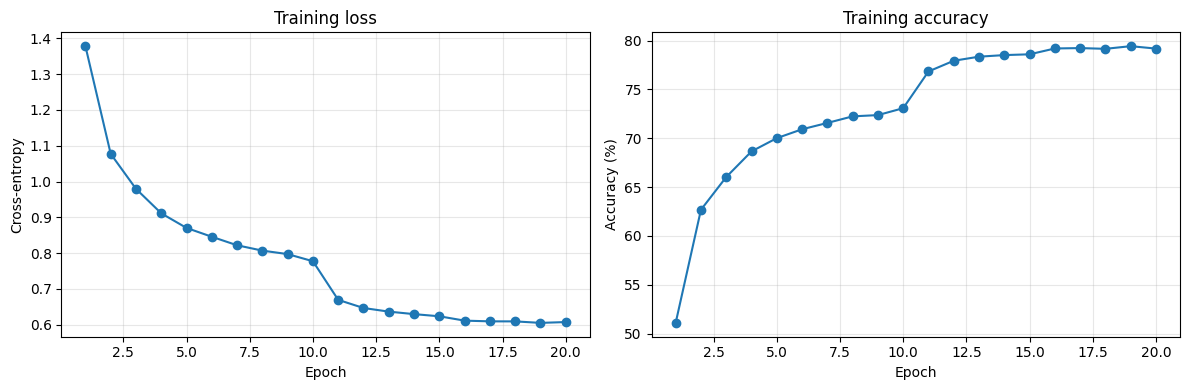

In [40]:
epochs_seen = history["epoch"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_seen, history["train_loss"], marker="o")
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")
axes[0].grid(alpha=0.3)
axes[1].plot(
    epochs_seen,
    np.asarray(history["train_accuracy"]) * 100,
    marker="o",
)
axes[1].set_title("Training accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [41]:
test_result = evaluate(
    model=model,
    x=x_test,
    y=y_test,
    batch_size=batch_size,
    num_classes=num_classes,
)
confusion = test_result["confusion_matrix"]
per_class_accuracy = confusion.diagonal() / confusion.sum(axis=1)
print(f"Test loss:     {test_result['loss']:.4f}")
print(f"Test accuracy: {test_result['accuracy']:.2%}")
print("\nPer-class test accuracy:")
for name, accuracy in zip(class_names, per_class_accuracy):
    print(f"  {name:>10}: {accuracy:.2%}")

metrics = {
    "test_loss": test_result["loss"],
    "test_accuracy": test_result["accuracy"],
    "per_class_accuracy": {
        name: float(accuracy)
        for name, accuracy in zip(class_names, per_class_accuracy)
    },
    "confusion_matrix": confusion.tolist(),
    "train_samples": len(x_train),
    "test_samples": len(x_test),
    "epochs": epochs,
    "batch_size": batch_size,
    "parameter_count": model.parameter_count(),
}
metrics_path = output_dir / "final_metrics.json"
with metrics_path.open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)
print("\nSaved metrics to:", metrics_path)

Test loss:     0.7944
Test accuracy: 73.59%

Per-class test accuracy:
    airplane: 76.50%
  automobile: 83.20%
        bird: 61.70%
         cat: 55.00%
        deer: 70.10%
         dog: 66.90%
        frog: 80.60%
       horse: 76.40%
        ship: 83.60%
       truck: 81.90%

Saved metrics to: c:\Users\hp\Documents\GitHub\visual-feature-learning\outputs\cifar10_baseline\final_metrics.json


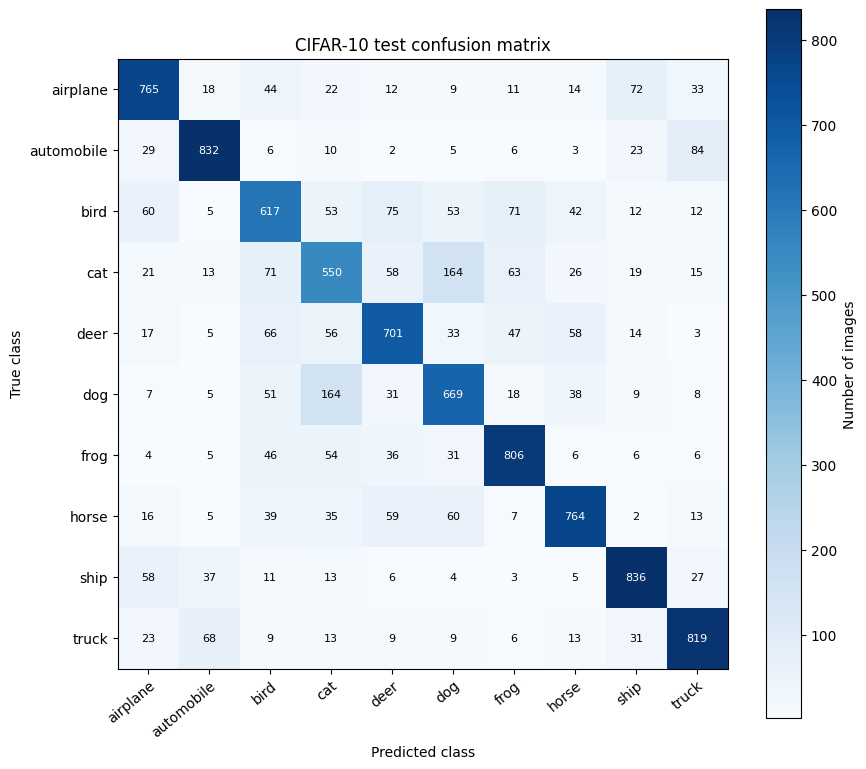

In [42]:
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(confusion, cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of images")
ax.set(
    xticks=np.arange(num_classes),
    yticks=np.arange(num_classes),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="True class",
    title="CIFAR-10 test confusion matrix",
)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")
threshold = confusion.max() / 2
for row in range(num_classes):
    for column in range(num_classes):
        ax.text(
            column,
            row,
            f"{confusion[row, column]}",
            ha="center",
            va="center",
            color="white" if confusion[row, column] > threshold else "black",
            fontsize=8,
        )
fig.tight_layout()
plt.show()